# Comparación de todos los métodos

SEED, Laplace, Temporal Ensemble, MC Dropout, Neural Process y Deep Ensemble, más un resumen de Conformal. Evaluaciones 0, 1 y 2 (cinco folds de test cada una) y el promedio de las tres. Los resultados se leen de la caché que crean los notebooks de cada método (`outputs/results_reports/analysis/`); si no existe, se calcula.

En los gráficos de barras, cada método tiene un punto por evaluación (0, 1 y 2, pequeños) y un rombo grande con el promedio de las tres. Las referencias de SEED cambian levemente entre métodos porque cada uno produce sus propios errores y detecciones.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidates if (p / 'configs' / 'default.yaml').exists()), Path.cwd())
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))
from eeg_uq import report

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)


def show(figure):
    display(figure)
    plt.close(figure)

all_results = {method: report.method_results(method) for method in report.METHODS}
table = report.comparison_table(all_results)

## 1. Tabla resumen

In [2]:
SUMMARY = ['F1 evento (%)', 'ECE clase positiva', 'NLL', 'AUROC errores: MI', 'AUPRC errores: MI', 'azar errores', 'AUROC errores: total',
           'FP vs TP AUROC MI', 'FP vs TP AUPRC MI', 'FP vs TP azar AUPRC', 'FN vs TP AUROC MI', 'FN vs TP AUPRC MI', 'FN vs TP azar AUPRC',
           '% epistémica (cerca de eventos)', 'ρ duración-incertidumbre']
for scope in report.SCOPES:
    print(scope)
    display(table.xs(scope, level='alcance')[SUMMARY].round(3))

Evaluación 0
Evaluación 1
Evaluación 2
Promedio eval 0, 1 y 2


,F1 evento (%),ECE clase positiva,NLL,AUROC errores: MI,AUPRC errores: MI,azar errores,AUROC errores: total,FP vs TP AUROC MI,FP vs TP AUPRC MI,FP vs TP azar AUPRC,FN vs TP AUROC MI,FN vs TP AUPRC MI,FN vs TP azar AUPRC,% epistémica (cerca de eventos),ρ duración-incertidumbre
método,,,,,,,,,,,,,,,
SEED,82.379,0.007,0.052,NaN,NaN,0.105,0.891,NaN,NaN,0.165,NaN,NaN,0.179,NaN,-0.661
Laplace,82.421,0.007,0.052,0.827,0.289,0.105,0.889,0.663,0.258,0.165,0.193,0.108,0.178,3.790,-0.470
Temporal Ensemble,82.503,0.007,0.052,0.815,0.284,0.104,0.891,0.467,0.176,0.164,0.302,0.129,0.178,0.780,-0.317
MC Dropout,82.408,0.006,0.051,0.876,0.364,0.105,0.891,0.817,0.380,0.155,0.475,0.182,0.189,2.033,-0.707
Neural Process,83.416,0.006,0.054,0.881,0.404,0.101,0.885,0.830,0.412,0.154,0.717,0.336,0.175,23.076,-0.495
Deep Ensemble,83.551,0.004,0.047,0.875,0.350,0.099,0.900,0.777,0.366,0.158,0.630,0.240,0.168,6.241,-0.471


,F1 evento (%),ECE clase positiva,NLL,AUROC errores: MI,AUPRC errores: MI,azar errores,AUROC errores: total,FP vs TP AUROC MI,FP vs TP AUPRC MI,FP vs TP azar AUPRC,FN vs TP AUROC MI,FN vs TP AUPRC MI,FN vs TP azar AUPRC,% epistémica (cerca de eventos),ρ duración-incertidumbre
método,,,,,,,,,,,,,,,
SEED,82.925,0.005,0.050,NaN,NaN,0.103,0.893,NaN,NaN,0.154,NaN,NaN,0.185,NaN,-0.627
Laplace,82.941,0.004,0.050,0.794,0.249,0.103,0.890,0.660,0.229,0.154,0.188,0.112,0.185,5.328,-0.446
Temporal Ensemble,82.991,0.005,0.050,0.815,0.282,0.103,0.894,0.492,0.183,0.154,0.318,0.136,0.184,0.815,-0.422
MC Dropout,82.934,0.004,0.049,0.876,0.360,0.104,0.892,0.820,0.360,0.146,0.505,0.204,0.192,2.078,-0.701
Neural Process,83.288,0.007,0.057,0.880,0.414,0.103,0.881,0.831,0.415,0.153,0.690,0.342,0.180,23.360,-0.507
Deep Ensemble,83.782,0.003,0.047,0.880,0.361,0.098,0.898,0.788,0.369,0.156,0.687,0.279,0.167,5.989,-0.488


,F1 evento (%),ECE clase positiva,NLL,AUROC errores: MI,AUPRC errores: MI,azar errores,AUROC errores: total,FP vs TP AUROC MI,FP vs TP AUPRC MI,FP vs TP azar AUPRC,FN vs TP AUROC MI,FN vs TP AUPRC MI,FN vs TP azar AUPRC,% epistémica (cerca de eventos),ρ duración-incertidumbre
método,,,,,,,,,,,,,,,
SEED,82.832,0.006,0.051,NaN,NaN,0.104,0.897,NaN,NaN,0.176,NaN,NaN,0.166,NaN,-0.617
Laplace,82.773,0.005,0.051,0.838,0.297,0.104,0.896,0.686,0.290,0.177,0.169,0.100,0.166,2.858,-0.419
Temporal Ensemble,82.940,0.005,0.051,0.815,0.283,0.103,0.897,0.492,0.201,0.174,0.316,0.122,0.165,0.772,-0.387
MC Dropout,82.829,0.005,0.050,0.878,0.367,0.104,0.896,0.814,0.384,0.166,0.486,0.173,0.175,2.009,-0.676
Neural Process,83.307,0.007,0.055,0.883,0.416,0.104,0.884,0.831,0.374,0.138,0.709,0.343,0.192,23.187,-0.479
Deep Ensemble,83.353,0.004,0.047,0.875,0.359,0.100,0.898,0.783,0.360,0.155,0.661,0.280,0.176,5.048,-0.372


,F1 evento (%),ECE clase positiva,NLL,AUROC errores: MI,AUPRC errores: MI,azar errores,AUROC errores: total,FP vs TP AUROC MI,FP vs TP AUPRC MI,FP vs TP azar AUPRC,FN vs TP AUROC MI,FN vs TP AUPRC MI,FN vs TP azar AUPRC,% epistémica (cerca de eventos),ρ duración-incertidumbre
método,,,,,,,,,,,,,,,
SEED,82.712,0.006,0.051,NaN,NaN,0.104,0.894,NaN,NaN,0.165,NaN,NaN,0.177,NaN,-0.635
Laplace,82.712,0.006,0.051,0.820,0.279,0.104,0.892,0.670,0.259,0.166,0.183,0.107,0.176,3.992,-0.445
Temporal Ensemble,82.812,0.006,0.051,0.815,0.283,0.103,0.894,0.484,0.187,0.164,0.312,0.129,0.176,0.789,-0.375
MC Dropout,82.724,0.005,0.050,0.877,0.364,0.104,0.893,0.817,0.375,0.156,0.489,0.187,0.185,2.040,-0.695
Neural Process,83.337,0.007,0.055,0.881,0.412,0.103,0.883,0.831,0.400,0.148,0.705,0.340,0.183,23.207,-0.493
Deep Ensemble,83.562,0.004,0.047,0.877,0.357,0.099,0.899,0.783,0.365,0.156,0.659,0.266,0.170,5.759,-0.444


## 2. Detección y calibración

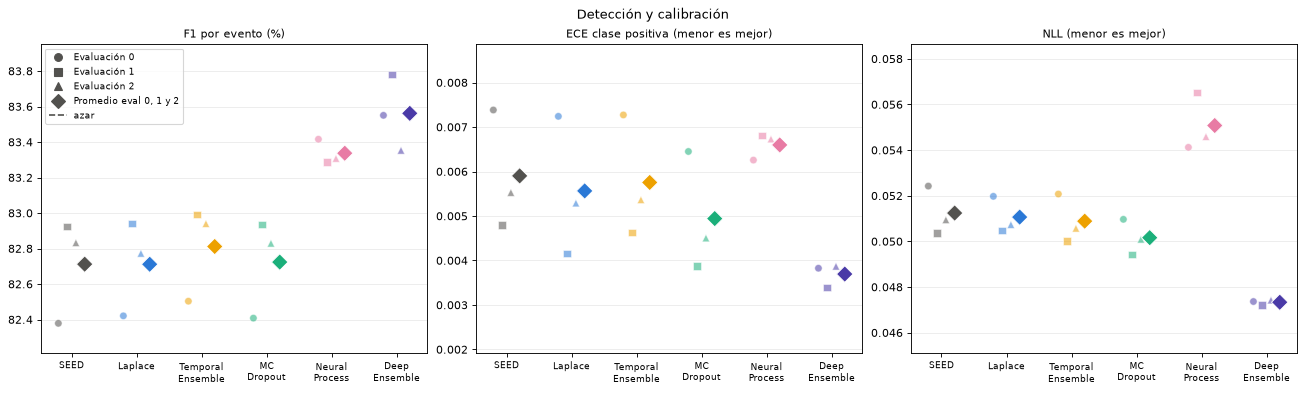

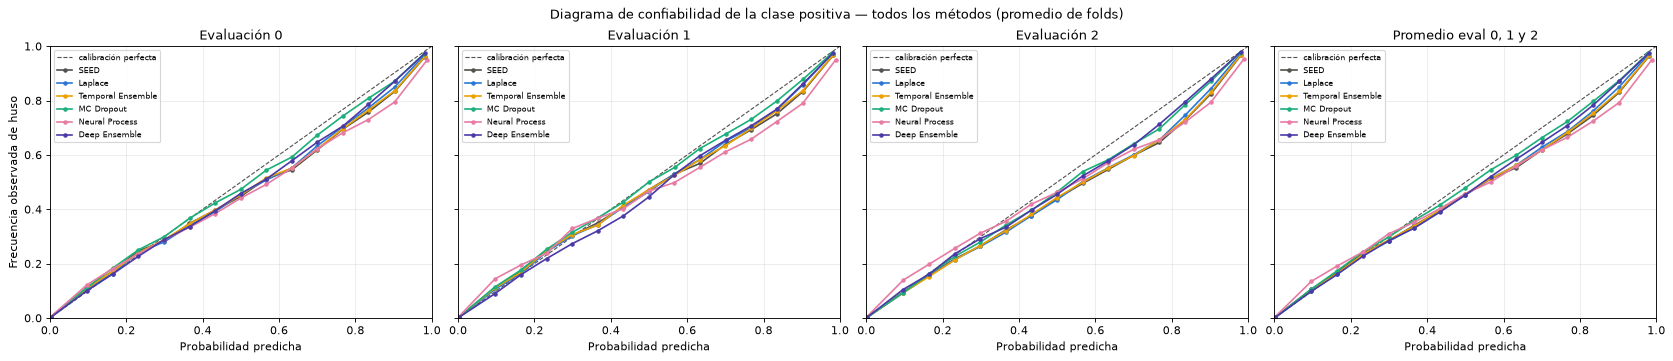

In [3]:
show(report.plot_method_bars(table, [('F1 evento (%)', 'F1 por evento (%)', None), ('ECE clase positiva', 'ECE clase positiva (menor es mejor)', None),
                                     ('NLL', 'NLL (menor es mejor)', None)], 'Detección y calibración'))
show(report.plot_reliability_all(all_results))

## 3. Descomposición de la incertidumbre

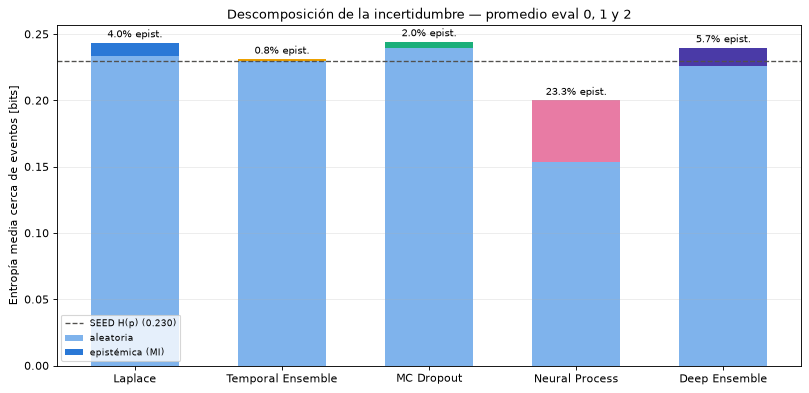

In [4]:
show(report.plot_decomposition_all(table))

## 4. ¿La incertidumbre detecta los errores? (timesteps cerca de eventos)

SEED no tiene MI (sin barra en esas columnas).

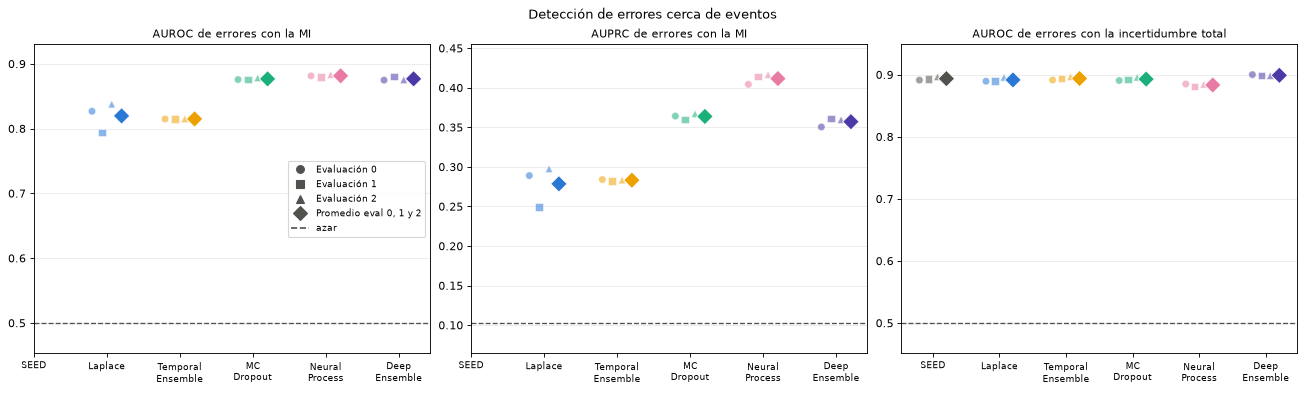

In [5]:
show(report.plot_method_bars(table, [('AUROC errores: MI', 'AUROC de errores con la MI', 0.5), ('AUPRC errores: MI', 'AUPRC de errores con la MI', 'azar errores'),
                                     ('AUROC errores: total', 'AUROC de errores con la incertidumbre total', 0.5)], 'Detección de errores cerca de eventos'))

## 5. Falsos positivos y falsos negativos

FP vs TP en el tramo predicho; FN vs TP en el tramo real. Primero con la MI, después con la incertidumbre total.

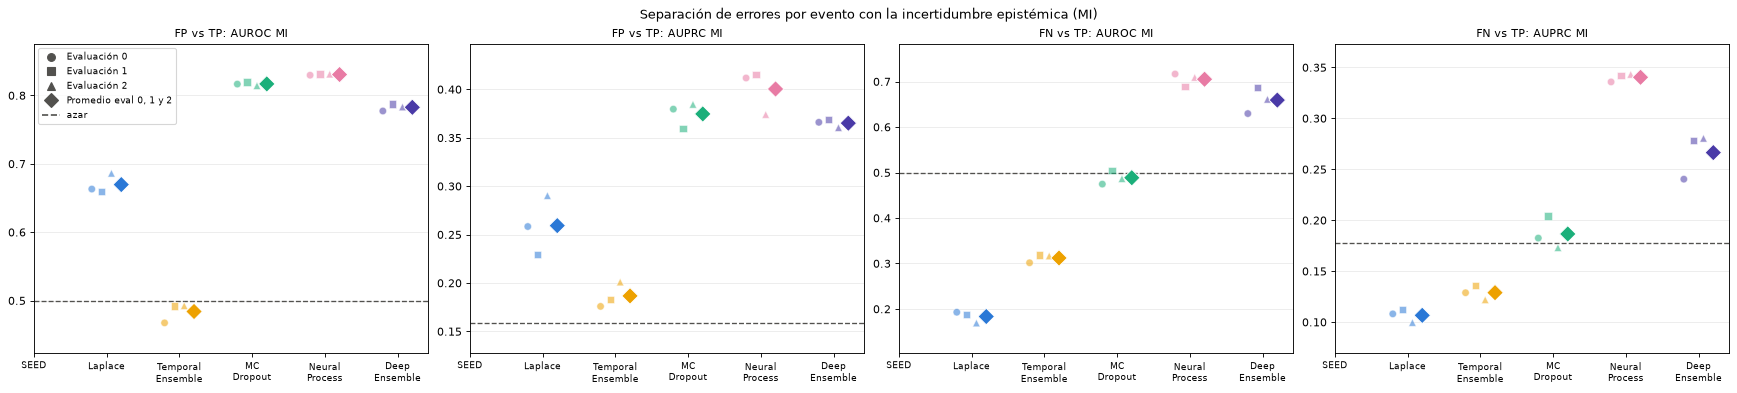

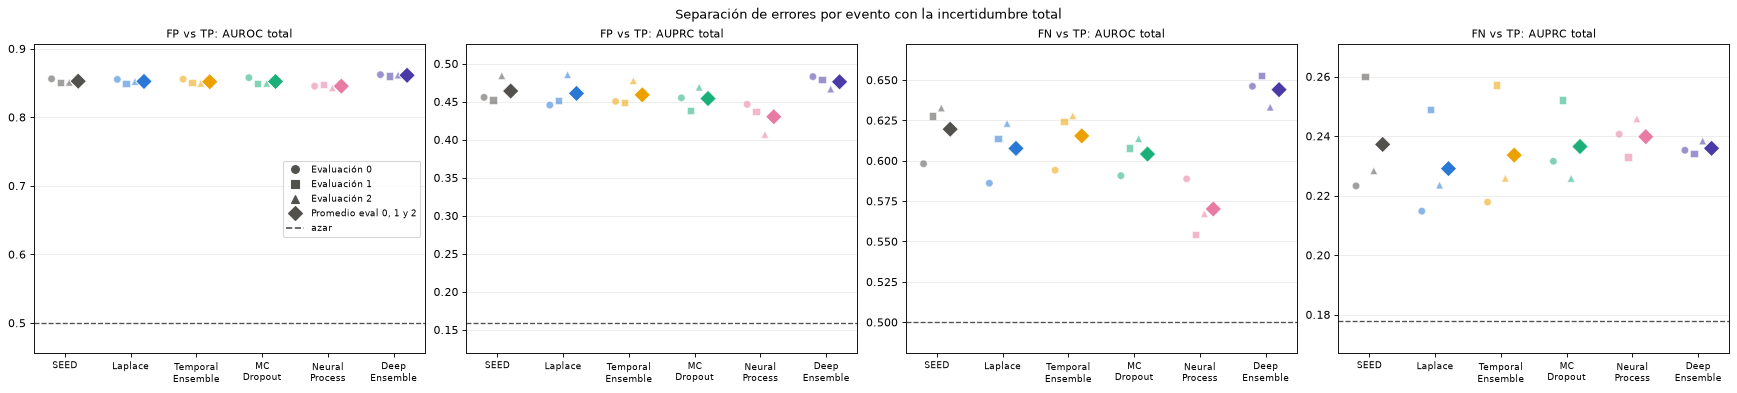

In [6]:
show(report.plot_method_bars(table, [('FP vs TP AUROC MI', 'FP vs TP: AUROC MI', 0.5), ('FP vs TP AUPRC MI', 'FP vs TP: AUPRC MI', 'FP vs TP azar AUPRC'),
                                     ('FN vs TP AUROC MI', 'FN vs TP: AUROC MI', 0.5), ('FN vs TP AUPRC MI', 'FN vs TP: AUPRC MI', 'FN vs TP azar AUPRC')],
                             'Separación de errores por evento con la incertidumbre epistémica (MI)'))
show(report.plot_method_bars(table, [('FP vs TP AUROC total', 'FP vs TP: AUROC total', 0.5), ('FP vs TP AUPRC total', 'FP vs TP: AUPRC total', 'FP vs TP azar AUPRC'),
                                     ('FN vs TP AUROC total', 'FN vs TP: AUROC total', 0.5), ('FN vs TP AUPRC total', 'FN vs TP: AUPRC total', 'FN vs TP azar AUPRC')],
                             'Separación de errores por evento con la incertidumbre total'))

## 6. Gráficos de cajón por tipo de evento

Percentil dentro del fold (0 = la menor incertidumbre del fold, 1 = la mayor), para comparar métodos con escalas distintas. La línea punteada (0.5) es el azar; la línea roja dentro de cada caja es la media. En el título de cada panel, el AUROC de FP vs TP y de FN vs TP.

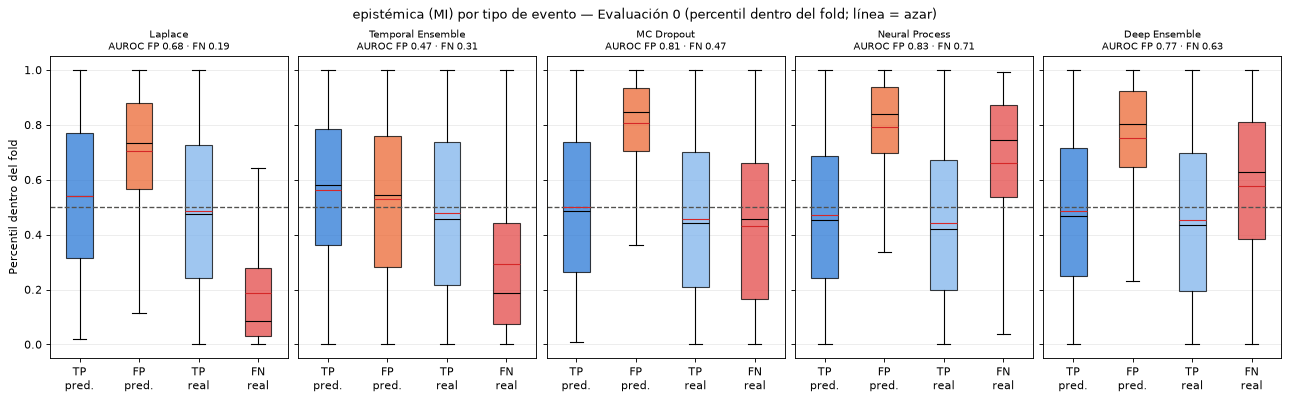

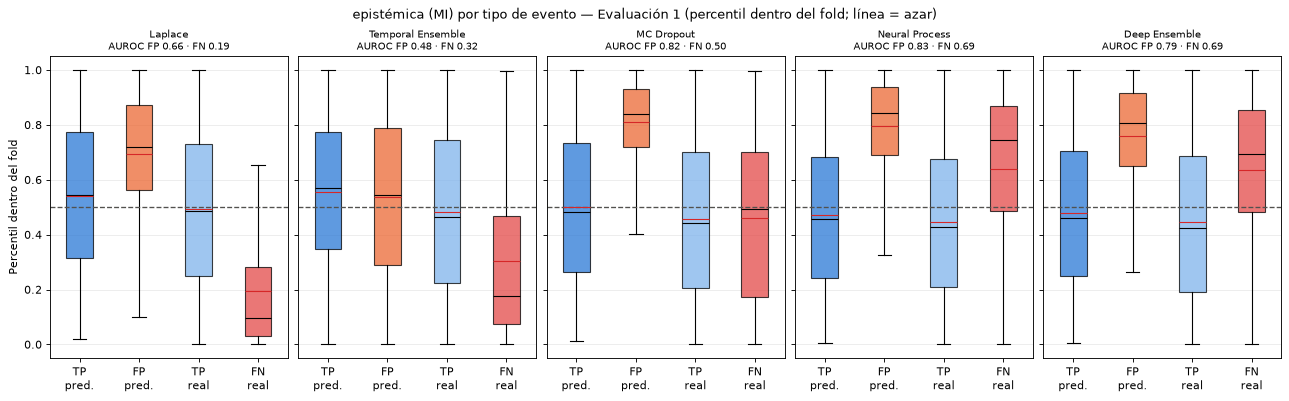

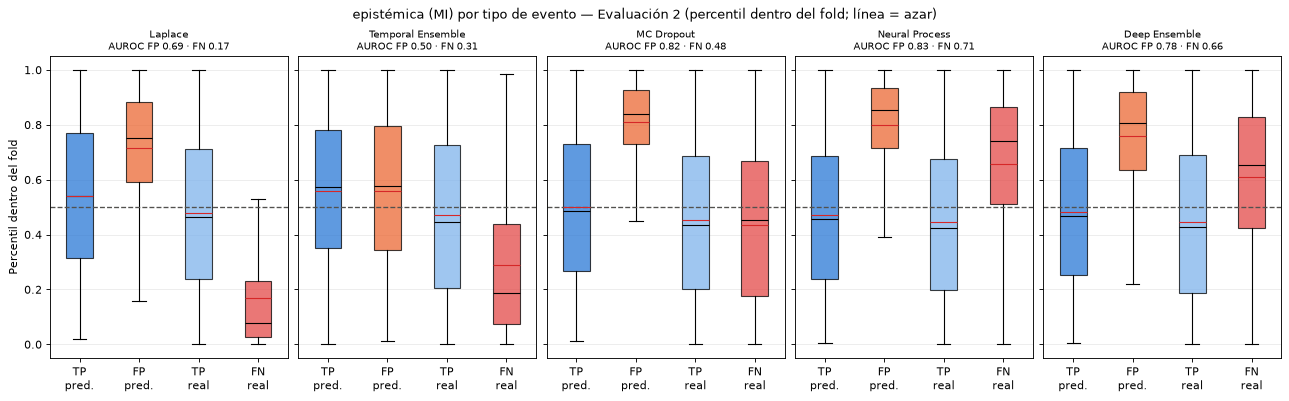

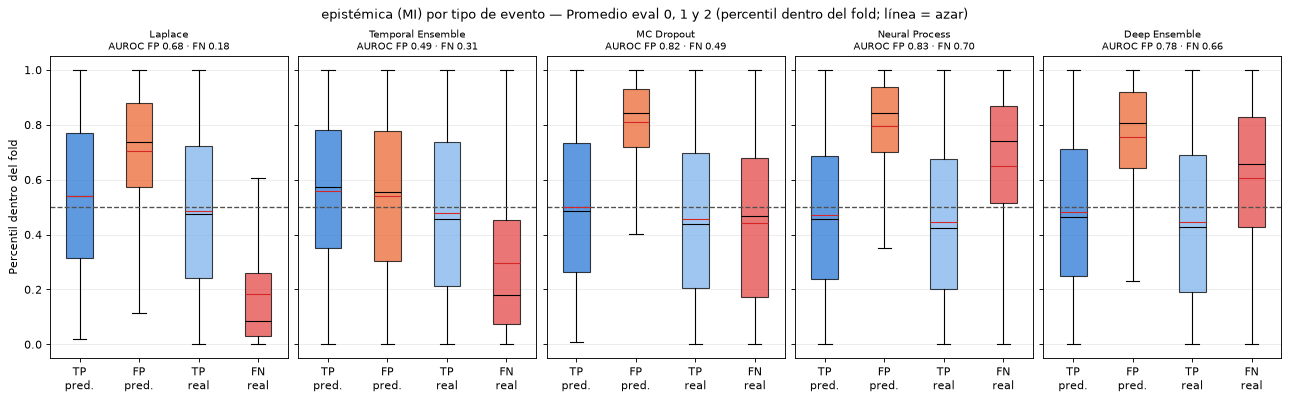

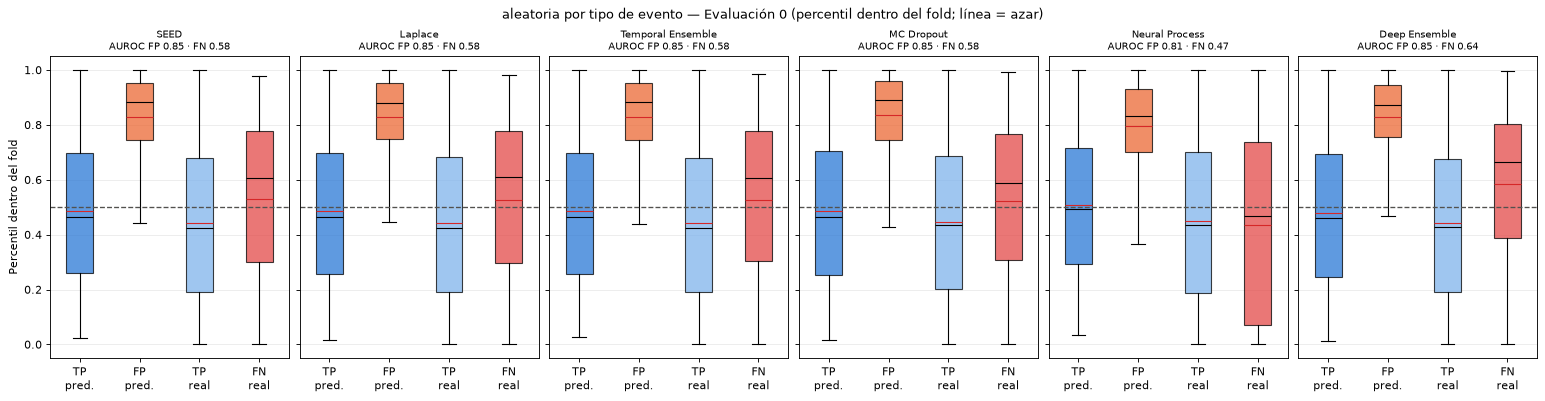

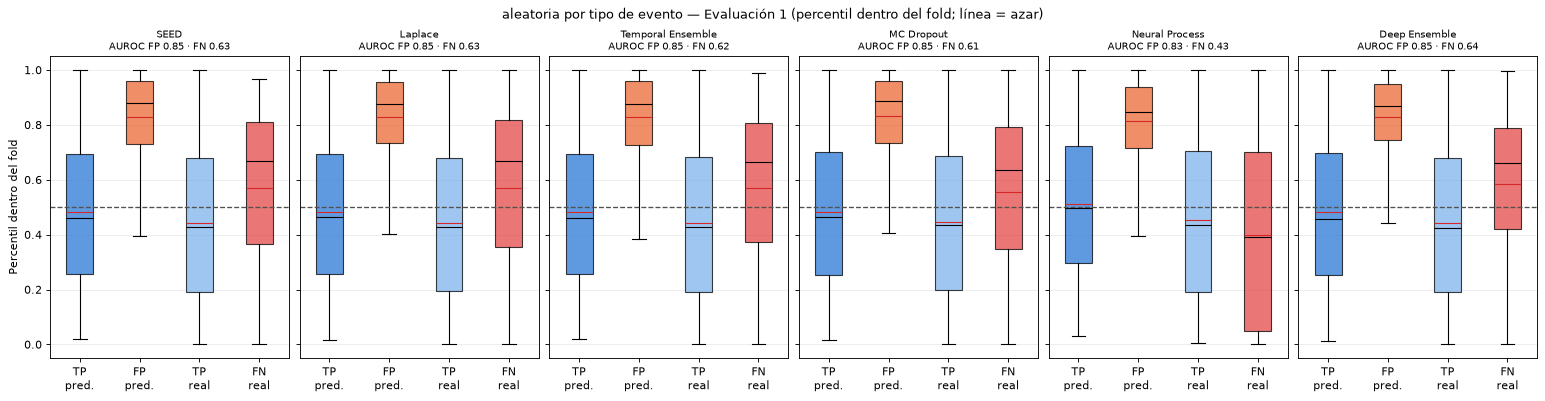

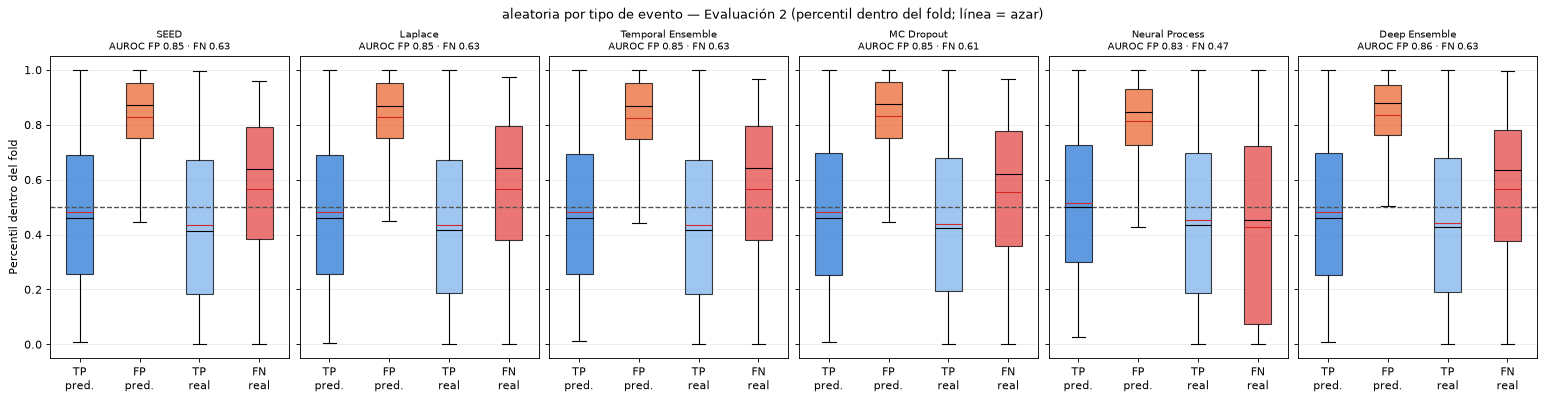

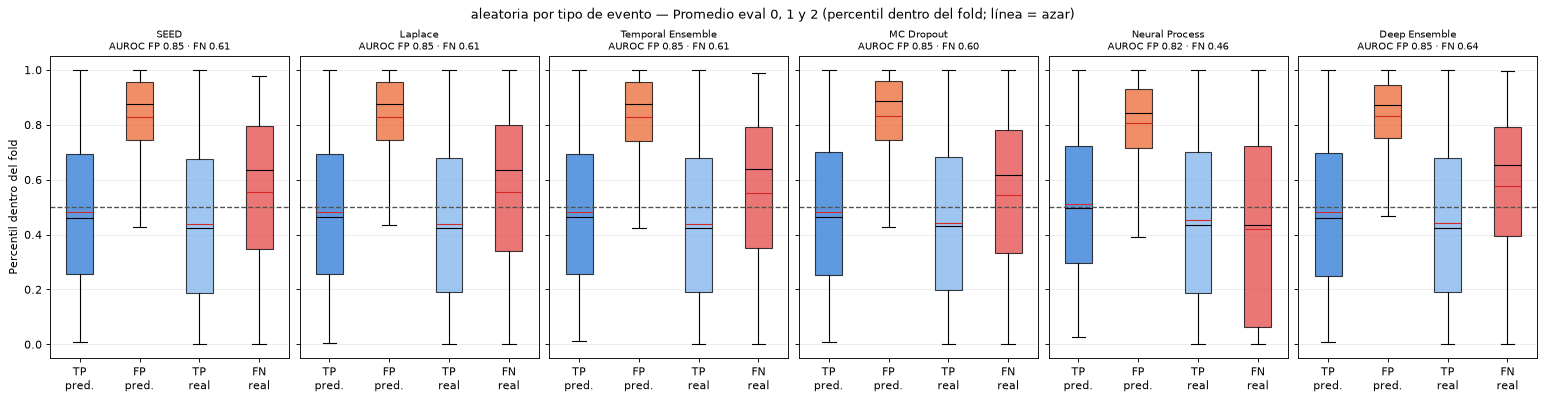

In [7]:
for measure in ('epistémica (MI)', 'aleatoria'):
    for scope in report.SCOPES:
        show(report.plot_event_boxes_all(all_results, measure, scope))

## 7. Usos automáticos y con revisión

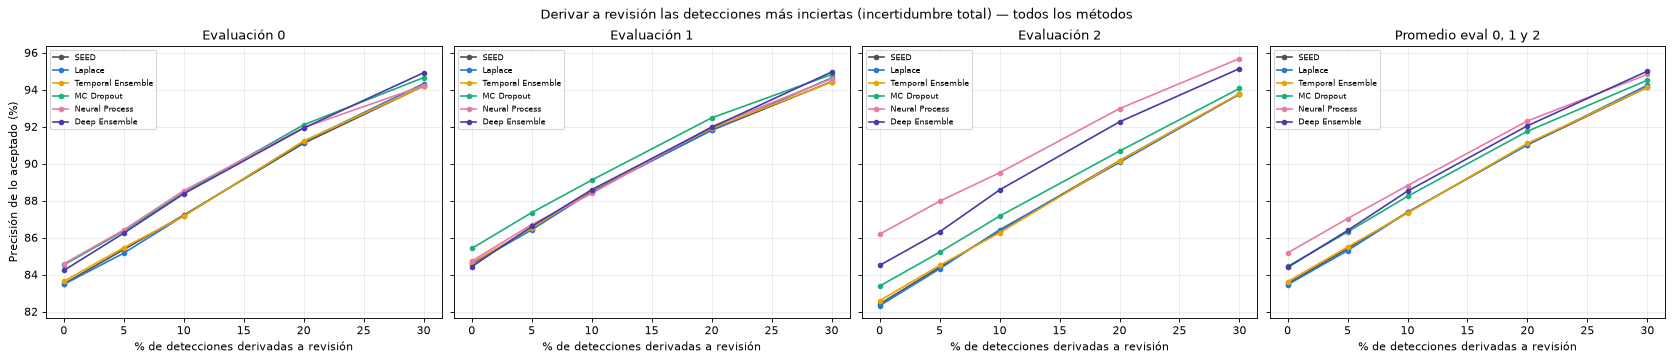

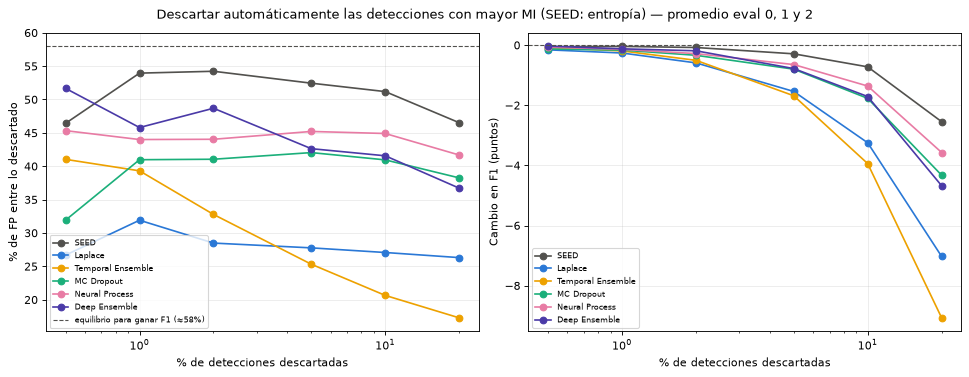

In [8]:
show(report.plot_deferral_all(all_results))
show(report.plot_rejection_all(all_results))

## 8. Conformal

In [9]:
conformal = report.conformal_results()
for alpha in (0.05, 0.10):
    print('alpha = {:.2f}'.format(alpha))
    display(report.by_evaluation(conformal[conformal['alpha'] == alpha], ['cobertura objetivo', 'cobertura total', 'cobertura husos', 'cobertura fondo', 'vacíos (abstención)']))

alpha = 0.05
alpha = 0.10


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
cobertura objetivo,0.95 ± 0,0.95 ± 0,0.95 ± 0,0.95 ± 3.4e-16
cobertura total,0.9485 ± 0.0095,0.9498 ± 0.0042,0.9502 ± 0.0046,0.9495 ± 0.0061
cobertura husos,0.5659 ± 0.082,0.5613 ± 0.05,0.5876 ± 0.083,0.5716 ± 0.069
cobertura fondo,0.969 ± 0.012,0.9707 ± 0.005,0.9694 ± 0.0067,0.9697 ± 0.0076
vacíos (abstención),0.04509 ± 0.01,0.04413 ± 0.0045,0.04338 ± 0.0043,0.0442 ± 0.0064


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
cobertura objetivo,0.9 ± 0,0.9 ± 0,0.9 ± 0,0.9 ± 1.1e-16
cobertura total,0.898 ± 0.02,0.8999 ± 0.0077,0.9001 ± 0.0098,0.8993 ± 0.013
cobertura husos,0.3049 ± 0.1,0.295 ± 0.054,0.3314 ± 0.085,0.3104 ± 0.078
cobertura fondo,0.9298 ± 0.022,0.9323 ± 0.0067,0.9304 ± 0.01,0.9308 ± 0.014
vacíos (abstención),0.1005 ± 0.02,0.09891 ± 0.0079,0.09862 ± 0.0097,0.09934 ± 0.013


## Hallazgos generales

Promedio de las evaluaciones 0, 1 y 2 (15 folds de test); los resultados son muy estables entre las tres evaluaciones.

| | F1 (%) | ECE | AUROC errores (total) | AUROC errores (MI) | FP vs TP (MI) | FN vs TP (MI) |
|---|---|---|---|---|---|---|
| SEED | 82.7 | 0.006 | 0.894 | — | — | — |
| Laplace | 82.7 | 0.006 | 0.892 | 0.820 | 0.67 | 0.18 |
| Temporal Ensemble | 82.8 | 0.006 | 0.894 | 0.815 | 0.48 | 0.31 |
| MC Dropout | 82.7 | 0.005 | 0.893 | 0.877 | 0.82 | 0.49 |
| Neural Process | 83.3 | 0.007 | 0.883 | **0.881** | **0.83** | **0.71** |
| **Deep Ensemble** | **83.6** | **0.004** | **0.899** | 0.877 | 0.78 | 0.66 |

1. **La incertidumbre de este problema es casi toda aleatoria y está en los bordes de los husos.** La parte epistémica es 1–6% en los métodos bayesianos (23% en Neural Process, con otra escala).
2. **El Deep Ensemble es el mejor método en conjunto:** mejor F1 (+0.9 puntos sobre SEED), mejor calibración y mejor incertidumbre total para detectar errores.
3. **Neural Process tiene la MI más útil**, pero empeora la calibración.
4. **MC Dropout es la mejor opción sin reentrenar.** Laplace de última capa y el Temporal Ensemble aportan poco o nada.
5. **Los dos tipos de error son distintos.** Los falsos positivos son ambigüedad visible: la incertidumbre de SEED ya los marca (AUROC 0.85). Los falsos negativos son errores silenciosos: SEED casi no los delata (0.62), y solo la MI de modelos con diversidad en toda la red (Neural Process 0.71, Deep Ensemble 0.66) recupera una parte.
6. **La incertidumbre no mejora el F1 como regla automática:** entre las detecciones más inciertas nunca hay más de ~58% de FP, el mínimo necesario. Su valor está en **priorizar la revisión** (revisar el 20% más incierto captura ~60% de los FP) y en **mejorar la probabilidad promediando modelos** (Deep Ensemble).
7. **Conformal cumple su garantía en promedio, pero no dentro de los husos** (57% de cobertura con α = 0.05).